# Plasticity plotting

This notebook generates plots to visualize neural plasticity post-patching by comparing outputs of a model finetuned using baseline data for baseline and post-patching data. The inference data is expected to exist under settings.INFERENCE_DIR, organized by model name and fold. The notebook allows you to specify which subjects and conditions to visualize.

In [2]:
import os

import numpy as np
from core import plotting
from core import io
from core import settings
import matplotlib.pyplot as plt
from scipy.stats import sem
import mne
from core import plot_data_processing as data_processor
from core.plot_data_processing import rename_chans_to_mne

In [3]:
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

model_name = "fixed_wavelet_huber"
subjects = None # set to None to load all subjects
conditions = ["global"]  # set to None to load all conditions
trial_ids = None #[]  # set to None to load all trial ids
bands = None #[] # set to None to visualize all frequency bands


In [4]:
# select appropriate frequency bands based on user input
if bands is None:
    bands = list(settings.FREQ_BANDS.keys())
else:
    loaded = []
    for band in bands:
        for key in settings.FREQ_BANDS.keys():
            if band in key:
                loaded.append(key)
    bands = loaded

### Filter the inference data to only include the specified subjects, conditions, and trial ids

In [5]:

baseline_folds = []
baseline_merged = []
postpatch_folds = []
postpatch_merged = []

for i in range(1, 7):
    b_file_path = settings.INFERENCE_DIR / model_name / str(i) / "baseline_reconstruction.h5"
    p_file_path = settings.INFERENCE_DIR / model_name / str(i) / "postpatch_reconstruction.h5"


    b_fold_trials = io.load_inference_trials(b_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids)
    baseline_folds.append(b_fold_trials)
    baseline_merged.extend(b_fold_trials)
    p_fold_trials = io.load_inference_trials(p_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids)
    postpatch_folds.append(p_fold_trials)
    postpatch_merged.extend(p_fold_trials)


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filteri

# Plotting the difference between baseline and post-patching performance

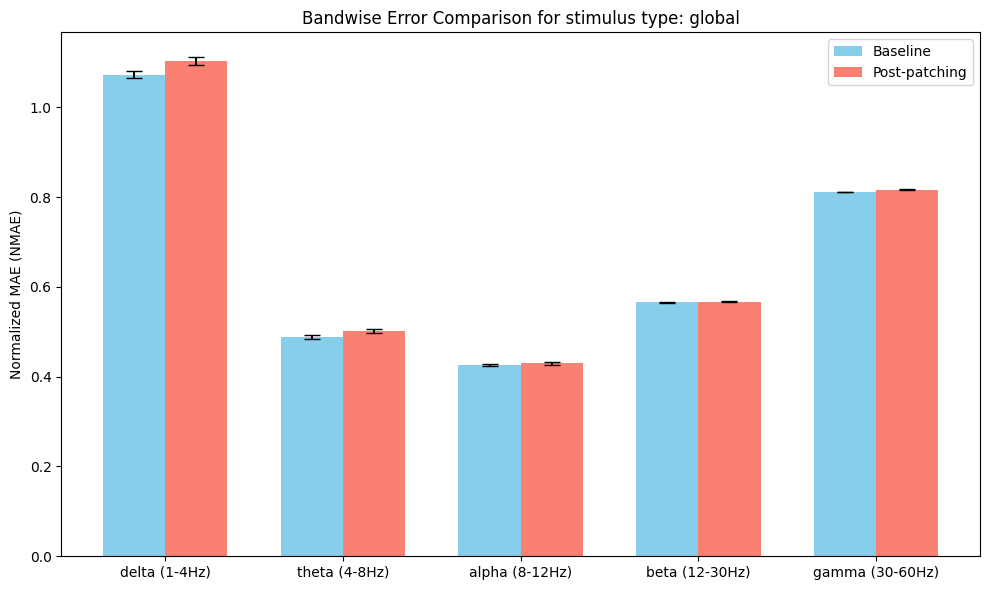

In [6]:


baseline_means, baseline_sems, _ = data_processor.get_bandwise_metric_stats(baseline_merged, metric_name="nmae_bandwise", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems, _ = data_processor.get_bandwise_metric_stats(postpatch_merged, metric_name="nmae_bandwise", bands=settings.FREQ_BANDS)

title = f'Bandwise Error Comparison for stimulus type: {", ".join(conditions)}'
width = 0.35

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=bands, width=width, means=means, sems=sems, labels=comparison_labels, title=title)
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_e_comparison", default_name=f"{model_name}_{'_'.join(conditions)}_error")


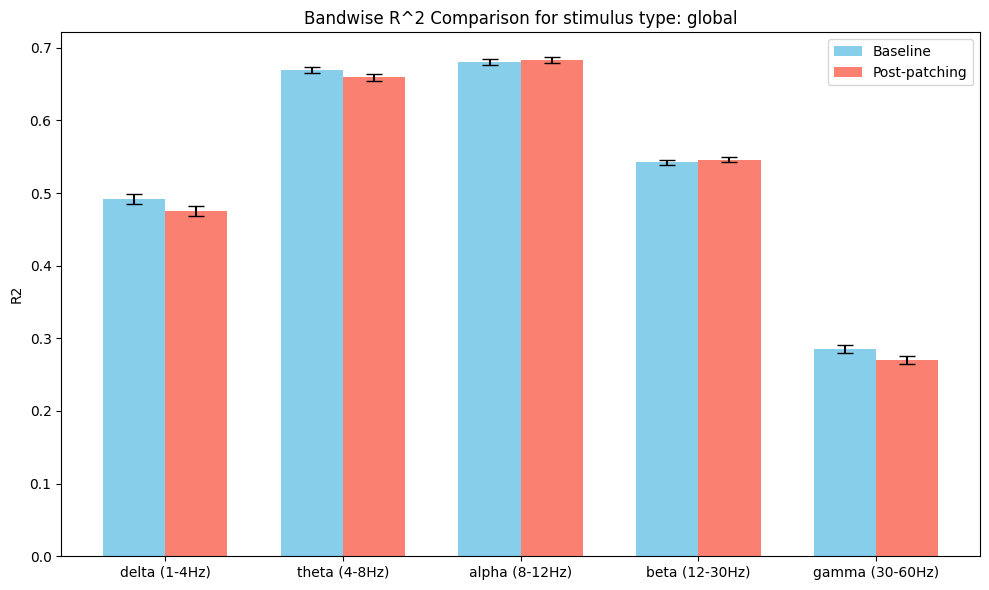

In [7]:


baseline_means, baseline_sems, _ = data_processor.get_bandwise_metric_stats(baseline_merged, metric_name="r2_bandwise", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems, _ = data_processor.get_bandwise_metric_stats(postpatch_merged, metric_name="r2_bandwise", bands=settings.FREQ_BANDS)

title = f'Bandwise R^2 Comparison for stimulus type: {", ".join(conditions)}'
width = 0.35
y_label = "R2"

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=bands, width=width, means=means, sems=sems, labels=comparison_labels, title=title, y_label=y_label)
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_e_comparison", default_name=f"{model_name}_{'_'.join(conditions)}_r2_error")


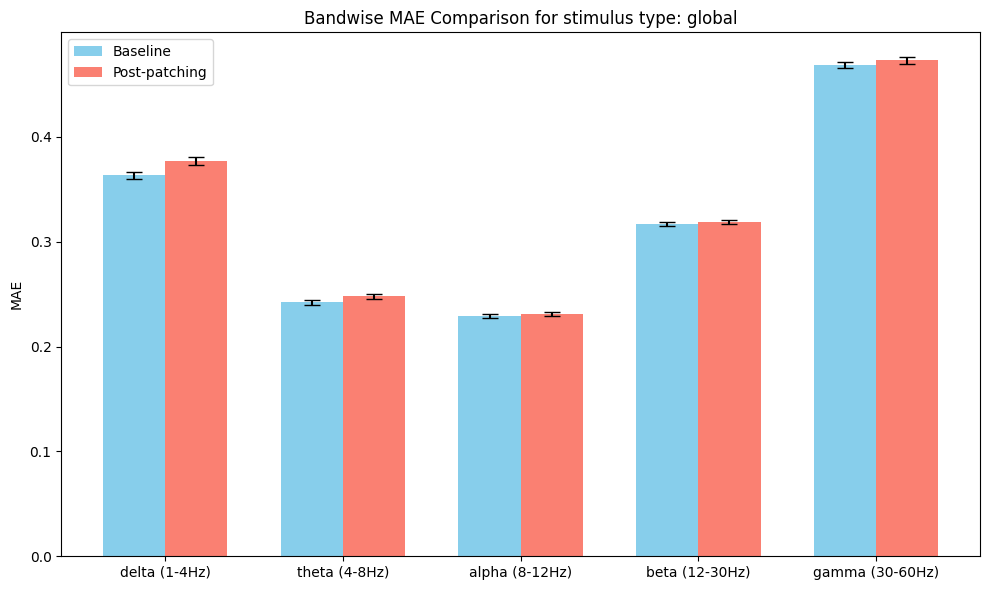

In [8]:
# Plotting the difference between baseline and post-patching performance


baseline_means, baseline_sems, _ = data_processor.get_bandwise_metric_stats(baseline_merged,
                                                                            metric_name="mae_bandwise",
                                                                            bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems, _ = data_processor.get_bandwise_metric_stats(postpatch_merged,
                                                                              metric_name="mae_bandwise",
                                                                              bands=settings.FREQ_BANDS)

title = f'Bandwise MAE Comparison for stimulus type: {", ".join(conditions)}'
width = 0.35
ylabel = "MAE"
ylim = None

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=bands, width=width, means=means, sems=sems, labels=comparison_labels,
                                    title=title, y_label=ylabel, ylim=ylim)
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE / "bandwise_e_mae_comparison",
                     default_name=f"{model_name}_{'_'.join(conditions)}_error")

## Single channel comparison viewer

In [9]:
input_metrics = []

input_metrics.append(data_processor.get_channel_viewer_metrics(baseline_merged, ["nmae", "nmae_bandwise"], ))
input_metrics.append(data_processor.get_channel_viewer_metrics(postpatch_merged, ["nmae", "nmae_bandwise"], ))

In [10]:

input_data = [baseline_merged, postpatch_merged]
styling_params = {
        "param_text": "",
        #"suptitle": f"Single channel reconstruction comparison for stimulus type: {', '.join(conditions)}",
        "suptitle": f"Single channel reconstruction comparison for stimulus type: ",
        "apply_log": False,
        "target_mode": "wavelet",
}
save_dir = settings.PLOT_INFERENCE/"single_channel_comparison"/f"{'_'.join(conditions)}"
plotting.single_channel_viewer(input_data, input_metrics, n_chans=settings.N_CHANNELS, styling_params=styling_params, save_dir=save_dir, bands=settings.FREQ_BANDS.keys(), freqs=settings.FREQS)

## Topomaps of global and bandwise error for given condition

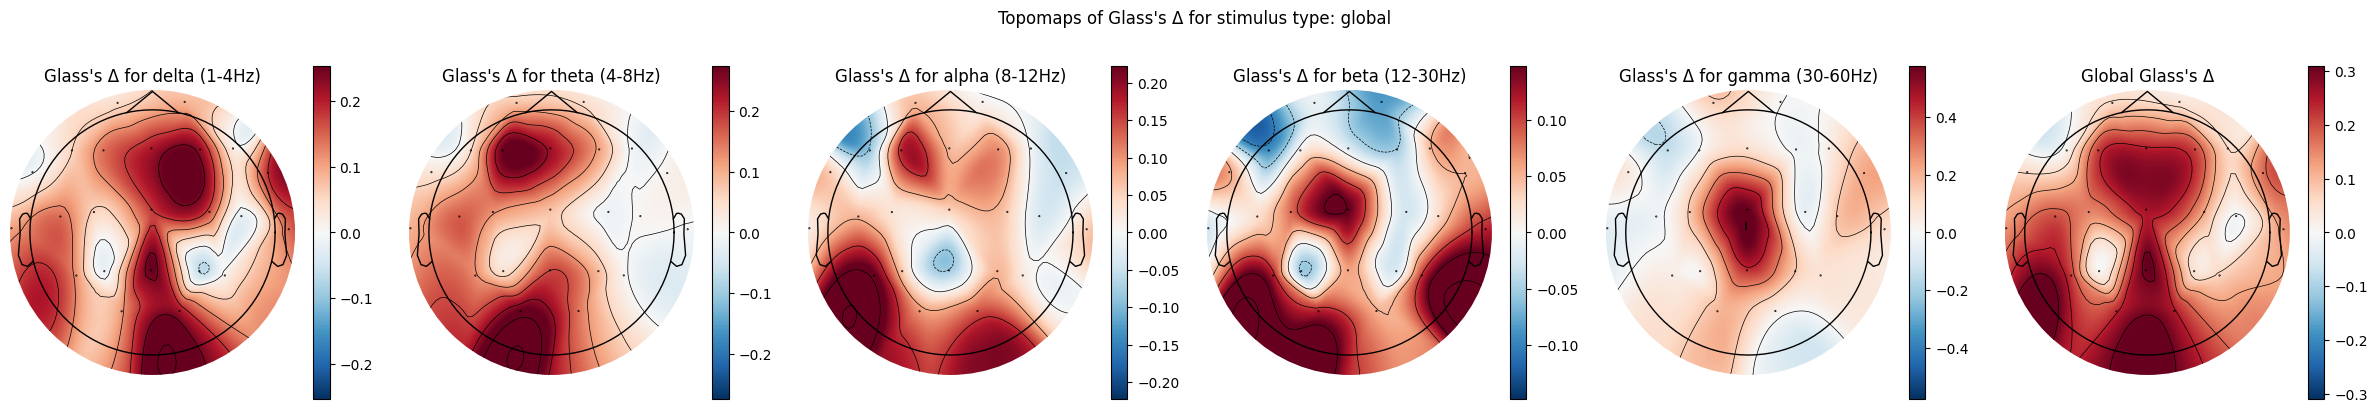

In [11]:


nmae_bw_b, _, std_bw_b = data_processor.get_channel_bandwise_metric_stats(baseline_merged, "nmae_bandwise", bands=settings.FREQ_BANDS)
nmae_bw_p, _, std_bw_p = data_processor.get_channel_bandwise_metric_stats(postpatch_merged, "nmae_bandwise", bands=settings.FREQ_BANDS)
glass_d_ch_bw = data_processor.calc_channel_bandwise_glass_delta(nmae_bw_b, nmae_bw_p, std_bw_b)

nmae_b, _, std_b = data_processor.get_channel_metric_stats(baseline_merged, "nmae")
nmae_p, _, std_p = data_processor.get_channel_metric_stats(postpatch_merged, "nmae")

glass_d_ch_bw["global"] = data_processor.calc_channel_glass_delta(nmae_b, nmae_p, std_b)


ch_names = [settings.CHORDER_STANDARD[i] for i in range(settings.N_CHANNELS)]

rename_chans_to_mne(ch_names)

info = mne.create_info(ch_names=ch_names, sfreq=settings.RSFREQ, ch_types='eeg') # sfreq is required but not relevant for static topomap
montage = mne.channels.make_standard_montage('standard_1005')
info.set_montage(montage)

# create 1x6 subplot for global MAE and each frequency band's MAE with topomap of Glass's delta values
fig, axes = plt.subplots(1, len(glass_d_ch_bw), figsize=(24, 4))

for i, (band, vals) in enumerate(glass_d_ch_bw.items()):

    max_val = max(np.abs(vals))
    vlim = (-max_val, max_val)
    im, _ = mne.viz.plot_topomap(vals, info, axes=axes[i], show=False, vlim=vlim, cmap="RdBu_r")
    if band == "global":
        axes[i].set_title(f"Global Glass's Δ")
    else:
        axes[i].set_title(f"Glass's Δ for {band}")
    fig.colorbar(im, ax=axes[i])
plt.suptitle(f"Topomaps of Glass's Δ for stimulus type: {', '.join(conditions)}", y=1.02)
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_topomaps", default_name=f"{model_name}_{'_'.join(conditions)}_topomaps")

plt.tight_layout()
plt.show()


## Plotting average power of trials where reconstruction NMAE was smaller for post-patching than baseline

In [12]:
# for band, ch_data in glass_d_ch_bw.items():
#     for ch_id, delta in enumerate(ch_data):
#         if delta < 0:
#             baseline_trials = [trial for trial in baseline_merged]
#             postpatch_trials = [trial for trial in postpatch_merged if trial.metrics.nmae_bandwise[band][ch_id] < trial.metrics.nmae_bandwise[band][ch_id]]


## plotting bandwise amplitude changes pre- and post-patching

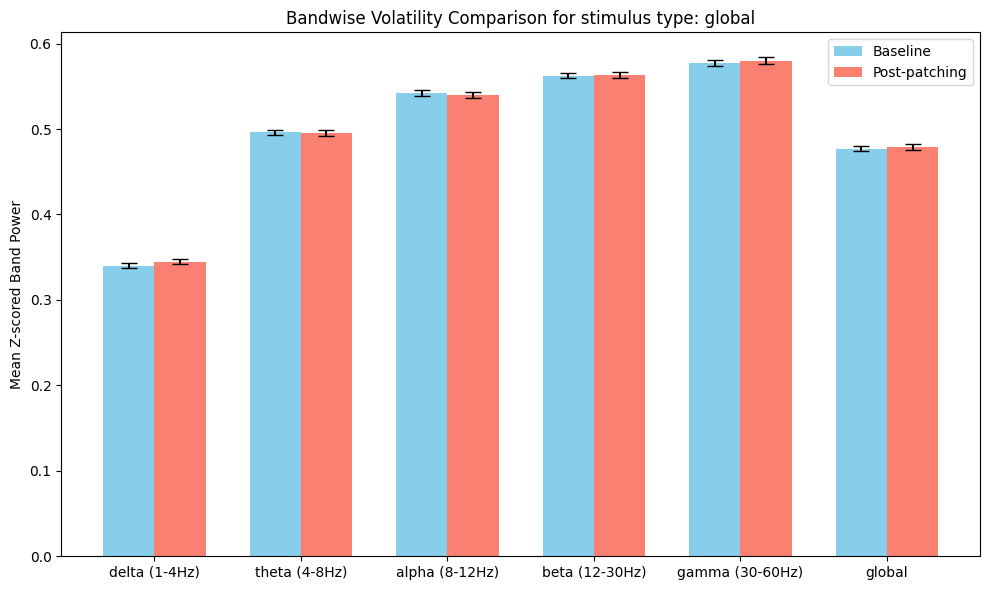

In [13]:
ampl_bw_b, sem_bw_b, _ = data_processor.get_bandwise_metric_stats(baseline_merged, bands=bands, metric_name="signal_volatility_bandwise")
ampl_bw_p, sem_bw_p, _ = data_processor.get_bandwise_metric_stats(postpatch_merged, bands=bands, metric_name="signal_volatility_bandwise")
ampl_bw_b["global"], sem_bw_b["global"], _ = data_processor.get_metric_stats(baseline_merged, metric_name="signal_volatility")
ampl_bw_p["global"], sem_bw_p["global"], _ = data_processor.get_metric_stats(postpatch_merged, metric_name="signal_volatility")


x_text = list(ampl_bw_b.keys())



fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(x_text))
title = f'Bandwise Volatility Comparison for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, ampl_bw_b.values(), width=width, yerr=sem_bw_b.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, ampl_bw_p.values(), width=width, yerr=sem_bw_p.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.set_xticklabels(x_text)

# Formatting
ax.set_ylabel('Mean Z-scored Band Power')
ax.set_title(title)
ax.legend()

plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_amplitude", default_name=f"{model_name}_{'_'.join(conditions)}_bw_amps")

plt.tight_layout()
plt.show()

## Subject-wise gamma NMAE comparison pre- and post-patching

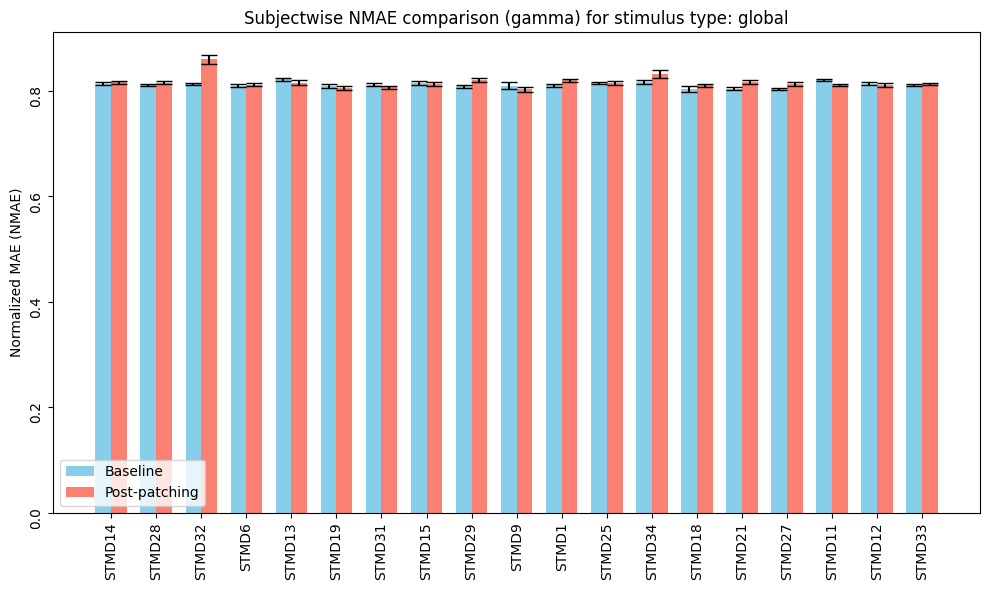

In [14]:
subjectwise_nmae_b, subjectwise_nmae_sem_b = data_processor.calc_subjectwise_metric_stats(baseline_merged, ["gamma (30-60Hz)"], metric="nmae")
subjectwise_nmae_p, subjectwise_nmae_sem_p = data_processor.calc_subjectwise_metric_stats(postpatch_merged, ["gamma (30-60Hz)"], metric="nmae")

band = 'gamma (30-60Hz)'

sb_baseline_nmae = {s: subjectwise_nmae_b[s][band] for s in subjectwise_nmae_b}
sb_baseline_sem  = {s: subjectwise_nmae_sem_b[s][band] for s in subjectwise_nmae_b}
sb_postpatch_nmae = {s: subjectwise_nmae_p[s][band] for s in subjectwise_nmae_b}
sb_postpatch_sem  = {s: subjectwise_nmae_sem_p[s][band] for s in subjectwise_nmae_b}

fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(subjectwise_nmae_b.keys()))
title = f'Subjectwise NMAE comparison (gamma) for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, sb_baseline_nmae.values(), width=width, yerr=sb_baseline_sem.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, sb_postpatch_nmae.values(), width=width, yerr=sb_postpatch_sem.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.tick_params(labelrotation=90)
ax.set_xticklabels(sb_baseline_nmae.keys())

# Formatting
ax.set_ylabel('Normalized MAE (NMAE)')
ax.set_title(title)
ax.legend()
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"subjectwise_e_comparison", default_name=f"{model_name}_{'_'.join(conditions)}_nmae_subjectwise_gamma")
plt.tight_layout()
plt.show()


## Channelwise NMAE comparison for a given subject and frequency band pre- and post-patching

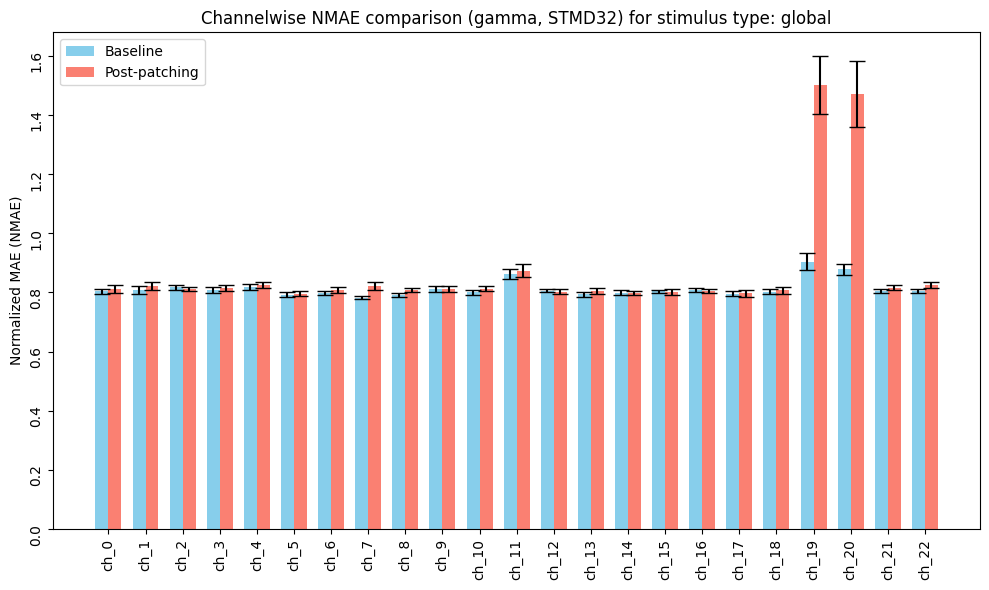

In [15]:
subjectwise_ch_nmae_b, subjectwise_ch_nmae_sem_b = data_processor.calc_subjectwise_channel_metric_stats(baseline_merged, ["gamma (30-60Hz)"], metric="nmae")

subjectwise_ch_nmae_p, subjectwise_ch_nmae_sem_p = data_processor.calc_subjectwise_channel_metric_stats(postpatch_merged, ["gamma (30-60Hz)"], metric="nmae")

sb_baseline_ch_nmae = {ch: band_dict['gamma (30-60Hz)'] for ch, band_dict in subjectwise_ch_nmae_b["STMD32"].items()}
sb_baseline_ch_sem  = {ch: band_dict['gamma (30-60Hz)'] for ch, band_dict in subjectwise_ch_nmae_sem_b["STMD32"].items()}
sb_postpatch_ch_nmae = {ch: band_dict['gamma (30-60Hz)'] for ch, band_dict in subjectwise_ch_nmae_p["STMD32"].items()}
sb_postpatch_ch_sem  = {ch: band_dict['gamma (30-60Hz)'] for ch, band_dict in subjectwise_ch_nmae_sem_p["STMD32"].items()}


fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(sb_baseline_ch_nmae.keys()))
title = f'Channelwise NMAE comparison (gamma, STMD32) for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, sb_baseline_ch_nmae.values(), width=width, yerr=sb_baseline_ch_sem.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, sb_postpatch_ch_nmae.values(), width=width, yerr=sb_postpatch_ch_sem.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.tick_params(labelrotation=90)
ax.set_xticklabels(sb_baseline_ch_nmae.keys())

# Formatting
ax.set_ylabel('Normalized MAE (NMAE)')
ax.set_title(title)
ax.legend()
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"channelwise_e_comparison", default_name=f"{model_name}_{'_'.join(conditions)}_nmae_stmd32_gamma")
plt.tight_layout()
plt.show()

## Plotting NMAE distribution of pre and post-patching trials

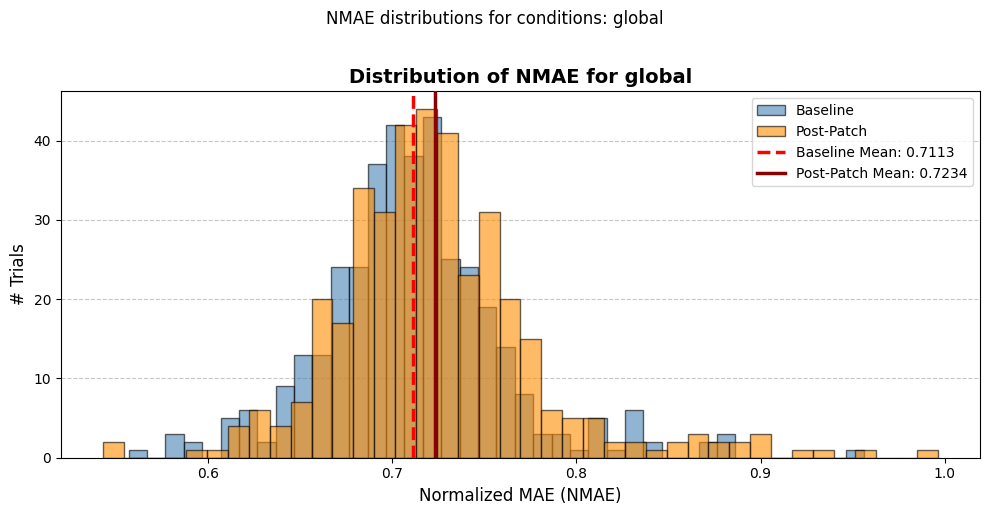

In [16]:
pre_nmaes = data_processor.extract_metric(baseline_merged, "nmae")
post_nmaes = data_processor.extract_metric(postpatch_merged, "nmae")

save_dir = settings.PLOT_INFERENCE / "nmae_dist_comparison"
plotting.distribution_viewer({"global": pre_nmaes}, {"global": post_nmaes}, title=f'NMAE distributions for conditions: {", ".join(conditions)}', save_dir=save_dir, save_name = f"{model_name}_{'_'.join(conditions)}_nmae_dist_global")



## Plotting bandwise NMAE distribution of pre and post-patching trials

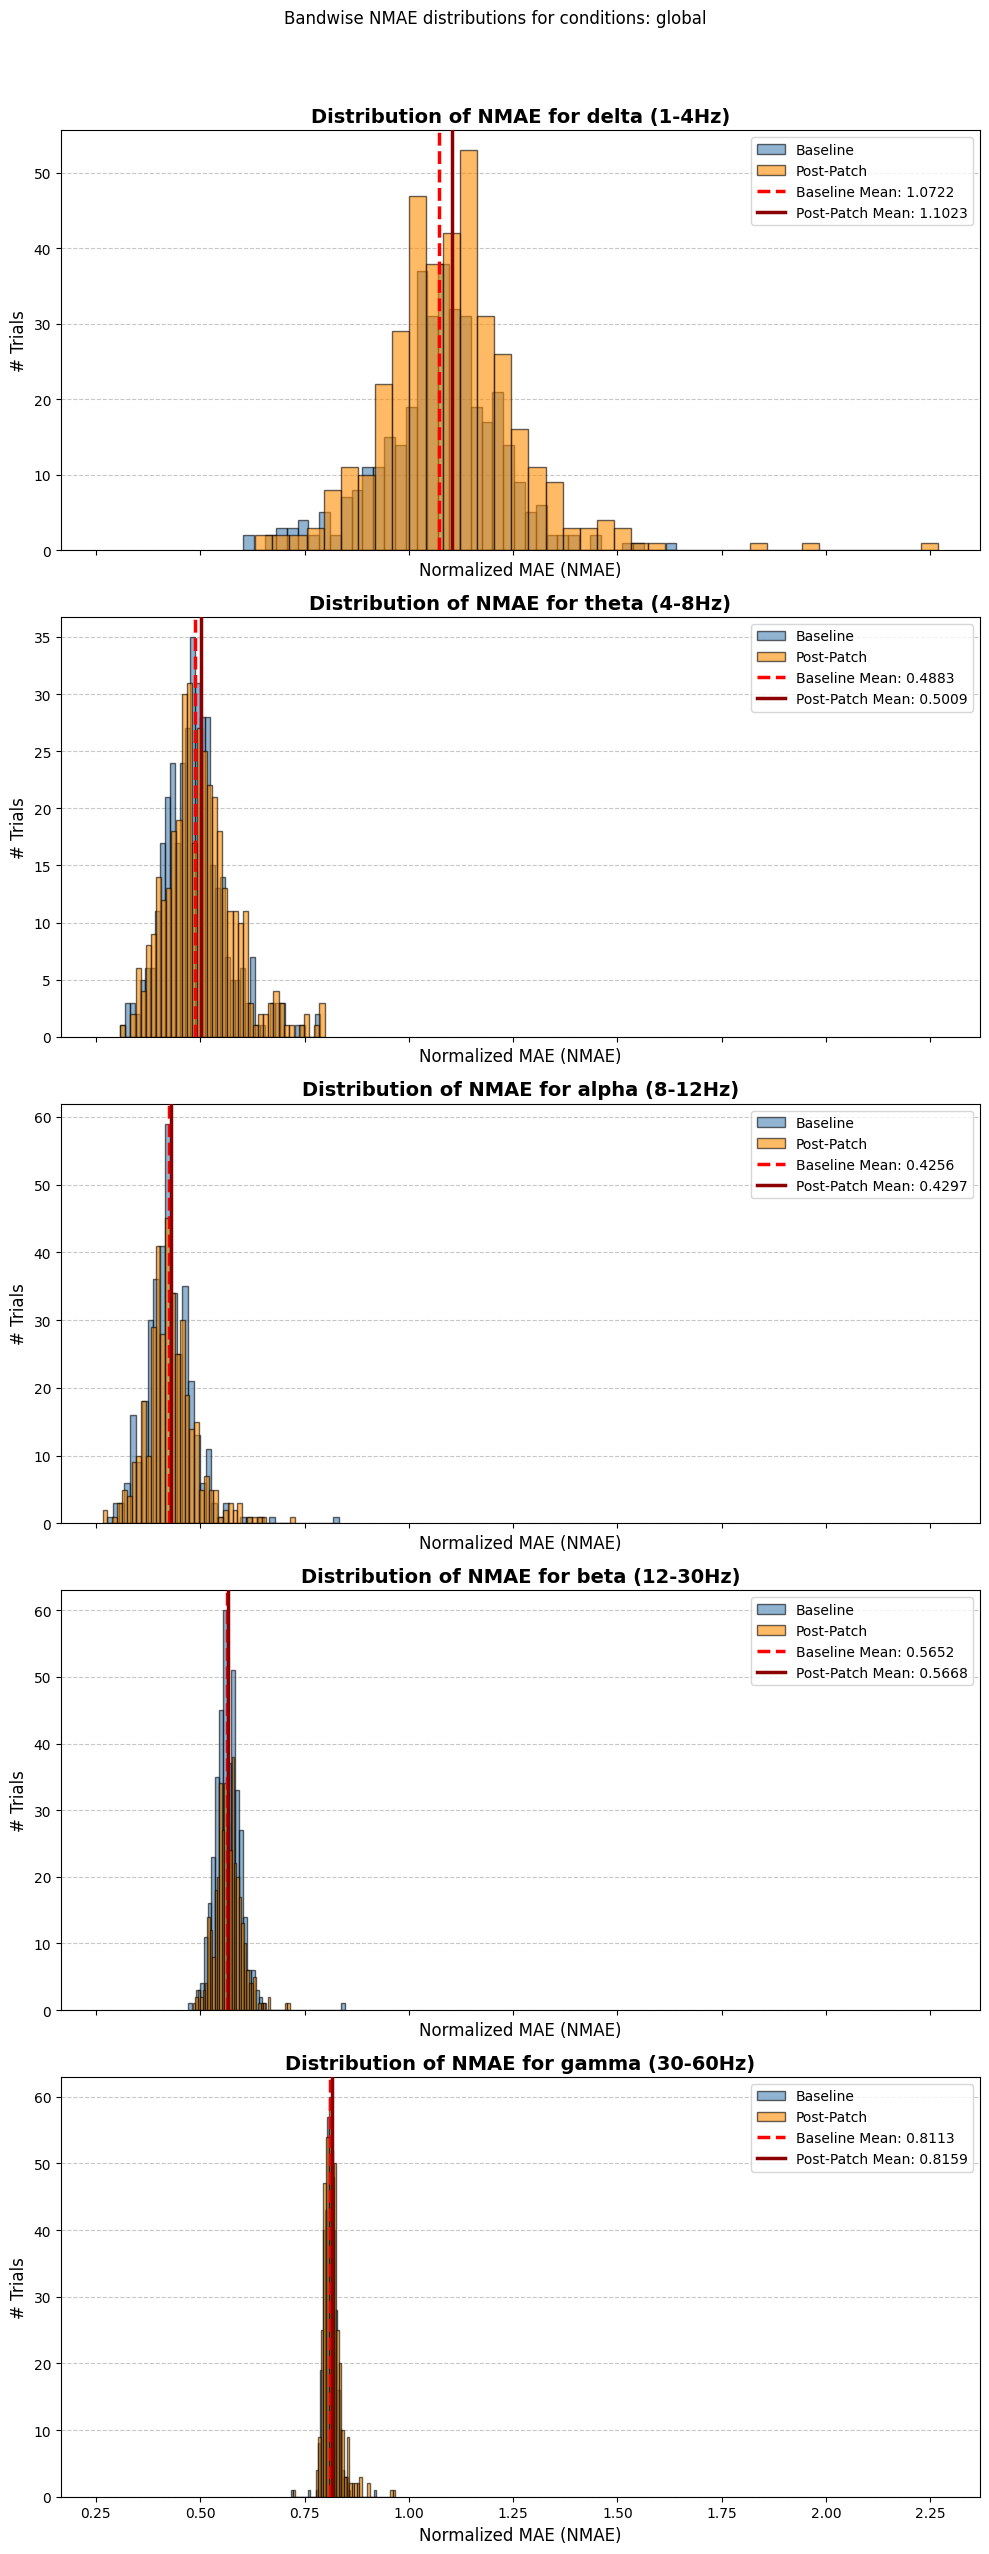

In [17]:
pre_nmaes_bw = data_processor.extract_metric(baseline_merged, "nmae_bandwise", bandwise=True, bands=settings.FREQ_BANDS)
post_nmaes_bw = data_processor.extract_metric(postpatch_merged, "nmae_bandwise", bandwise=True, bands=settings.FREQ_BANDS)

save_dir = settings.PLOT_INFERENCE / "nmae_dist_comparison"
plotting.distribution_viewer(pre_nmaes_bw, post_nmaes_bw, title=f'Bandwise NMAE distributions for conditions: {", ".join(conditions)}', save_dir=save_dir, save_name = f"{model_name}_{'_'.join(conditions)}_nmae_dist_bandwise")



## Correlation of signal volatility and NMAE pre- and post-patching

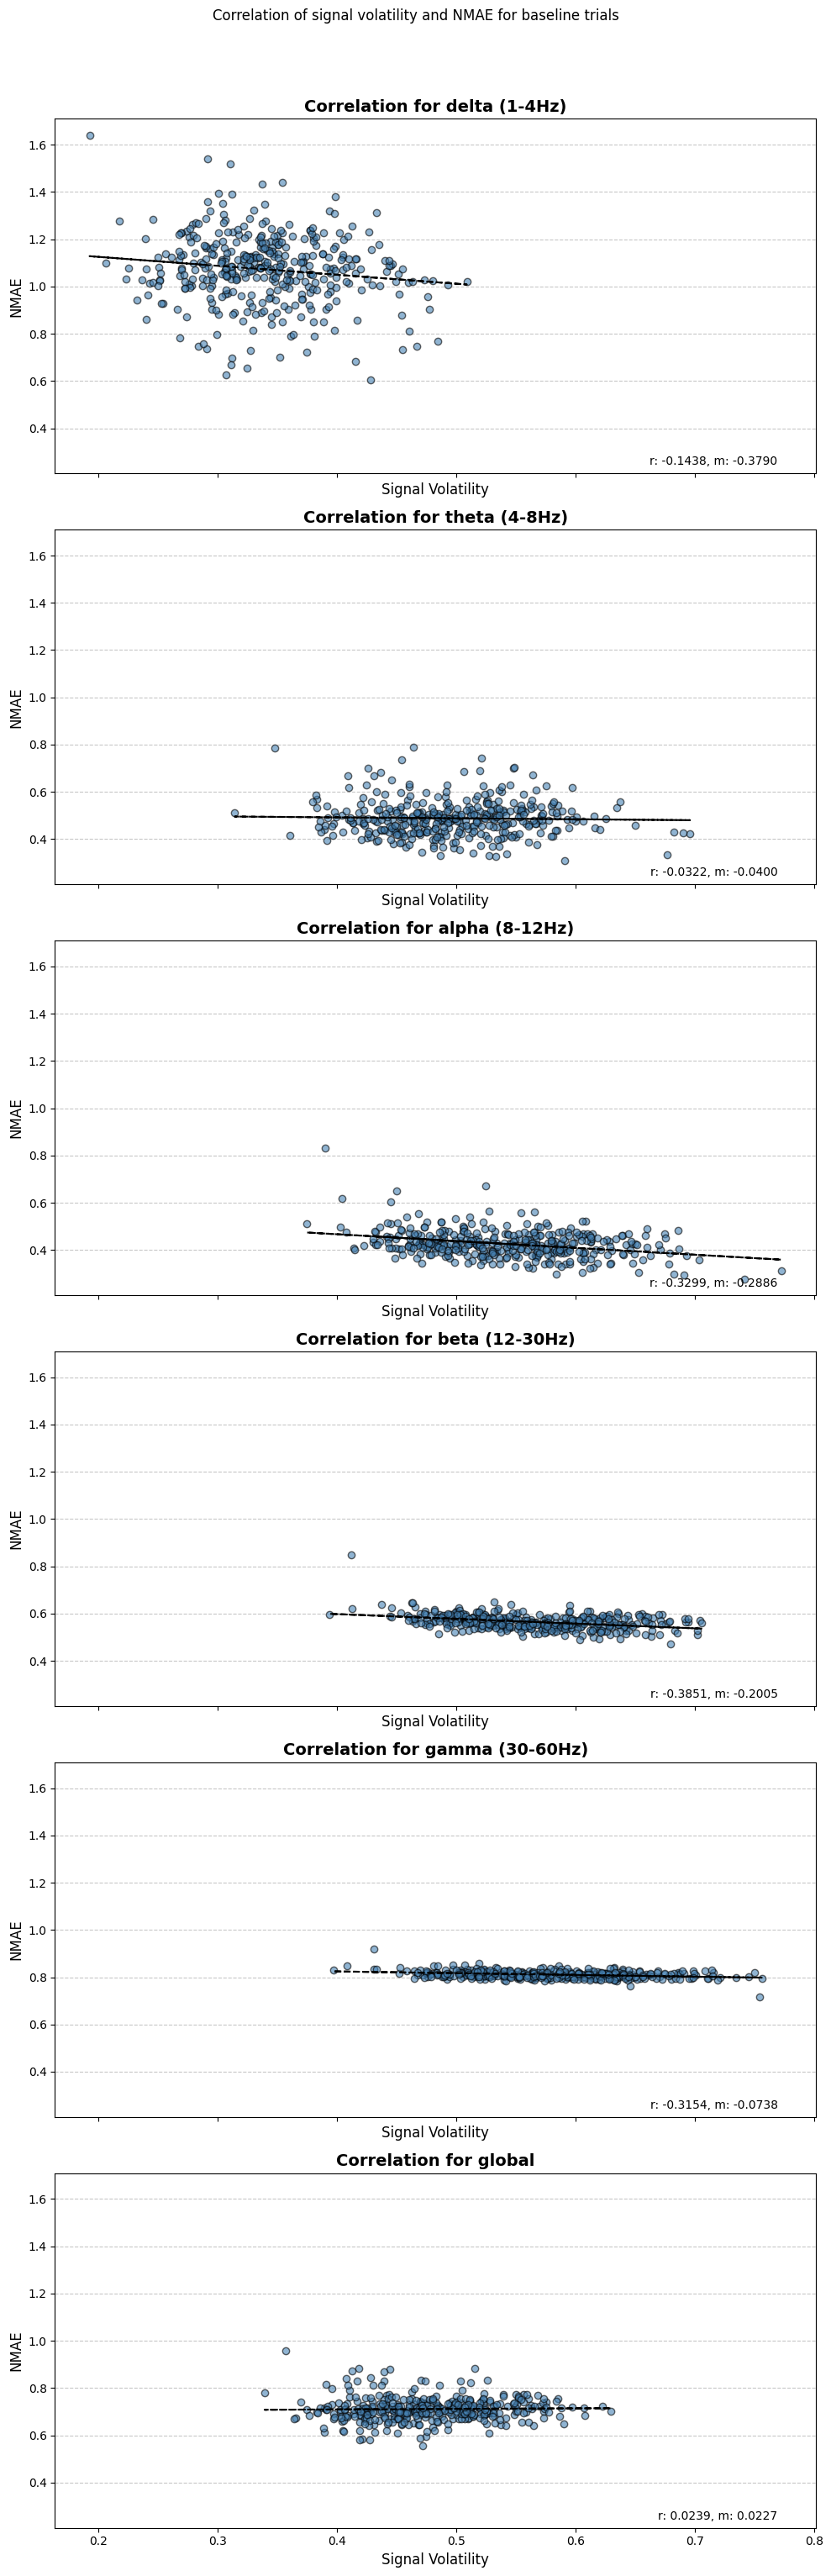

In [18]:
b_vols = data_processor.extract_metric(baseline_merged, "signal_volatility_bandwise", bands, bandwise=True)
b_vols["global"] = data_processor.extract_metric(baseline_merged, "signal_volatility", bandwise=False)

b_nmaes = pre_nmaes_bw.copy()
b_nmaes["global"] = pre_nmaes.copy()

plotting.correlation_plot(x=b_vols, y=b_nmaes, title=f'Correlation of signal volatility and NMAE for baseline trials', xlabel='Signal Volatility', ylabel='NMAE', save_dir=settings.PLOT_INFERENCE / "correlation_plots", save_name=f"{model_name}_{'_'.join(conditions)}_correlation_baseline")

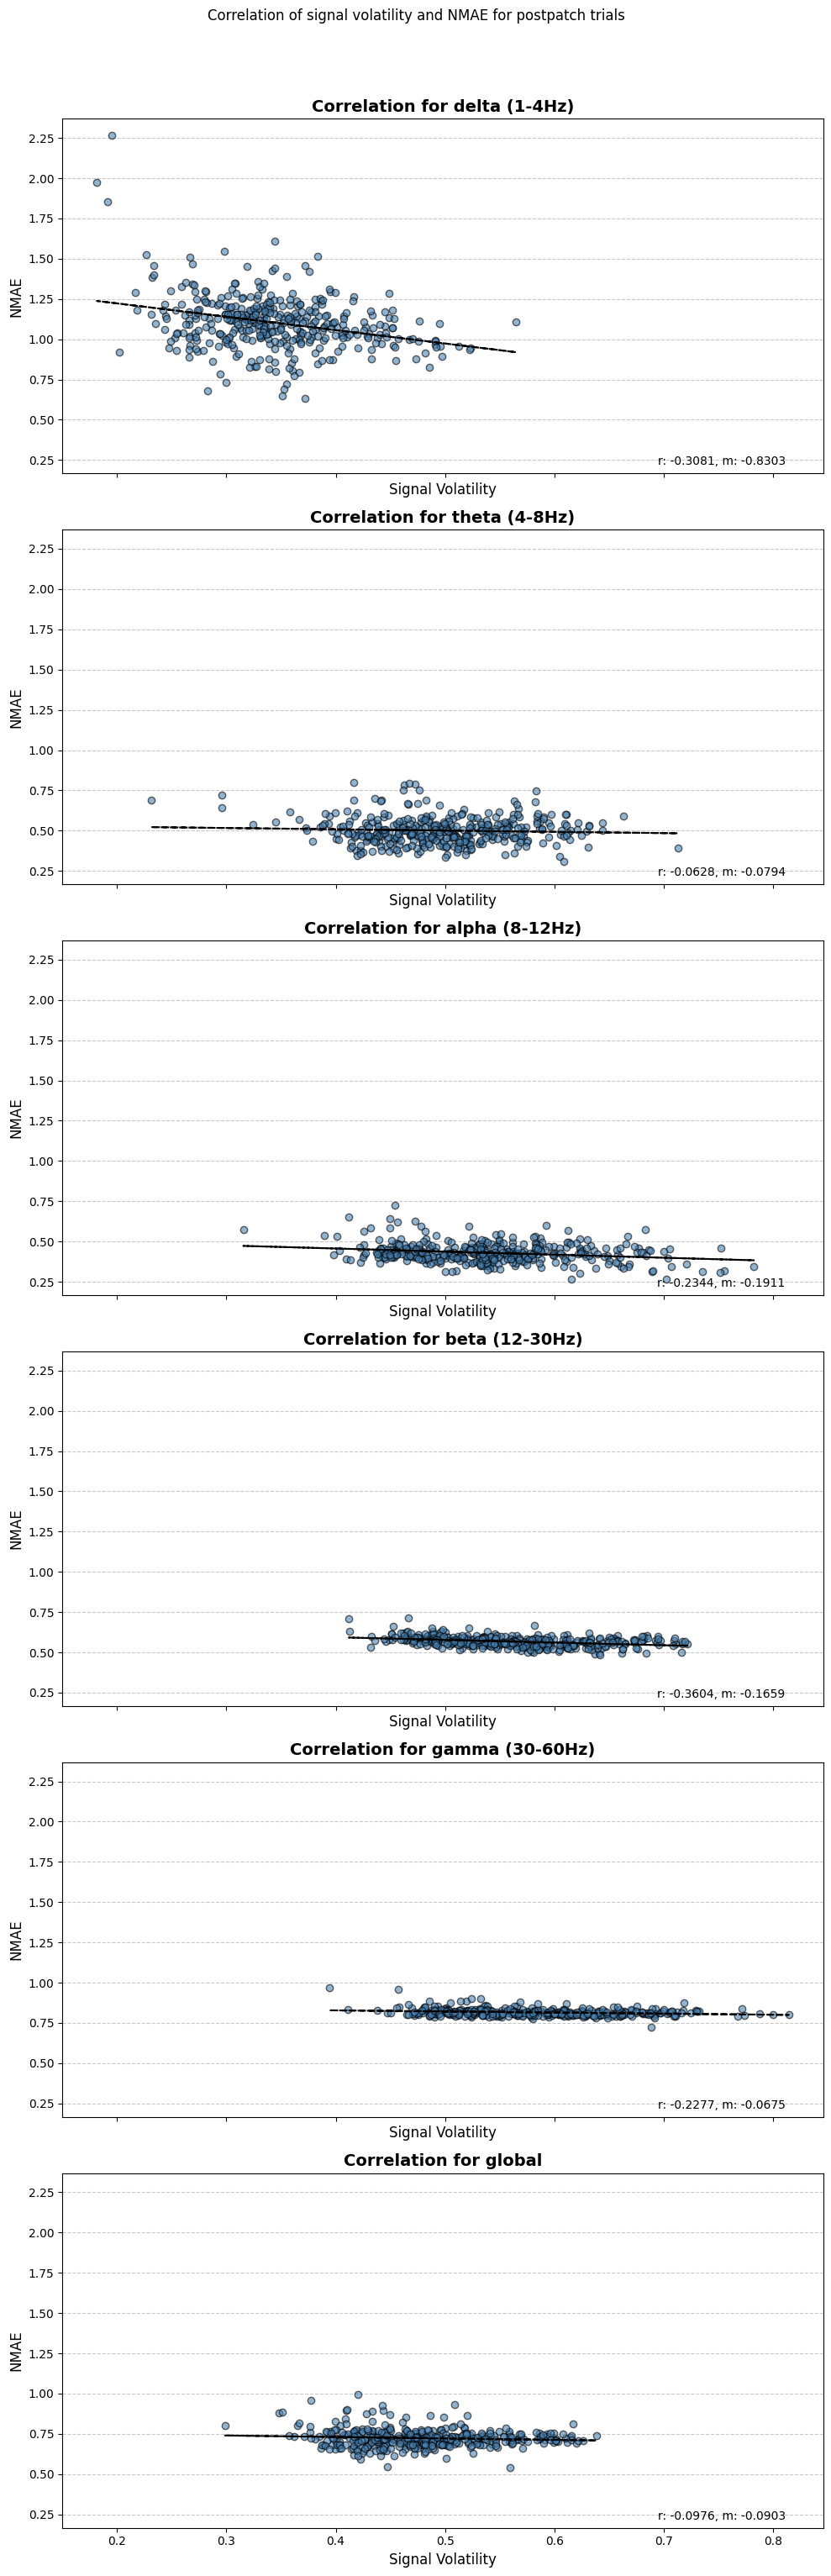

In [19]:
p_vols = data_processor.extract_metric(postpatch_merged, "signal_volatility_bandwise", bands, bandwise=True)
p_vols["global"] = data_processor.extract_metric(postpatch_merged, "signal_volatility", bandwise=False)

p_nmaes = post_nmaes_bw.copy()
p_nmaes["global"] = post_nmaes.copy()

plotting.correlation_plot(x=p_vols, y=p_nmaes, title=f'Correlation of signal volatility and NMAE for postpatch trials', xlabel='Signal Volatility', ylabel='NMAE', save_dir=settings.PLOT_INFERENCE / "correlation_plots", save_name=f"{model_name}_{'_'.join(conditions)}_correlation_postpatch")